In [3]:
import numpy as np
from TDD.TDD import TDD, Ini_TDD,Clear_TDD,set_index_order,get_unique_table_num,set_root_of_unit,get_count,cont,renormalize,Slicing2,Slicing
from TDD.TDD_Q import cir_2_tn,get_real_qubit_num,add_trace_line,add_inputs,add_outputs,gen_cir
from TDD.TN import Index,Tensor,TensorNetwork
import time
import random
from qiskit import QuantumCircuit,qasm2
import cProfile
from IPython.display import display, HTML,Image
# from PIL import Image
from PIL import Image as PILImage
import networkx as nx
import copy
from qiskit.circuit.library.standard_gates import HGate,U1Gate,U3Gate
from qiskit.quantum_info.operators import Operator
from qiskit.circuit.library import UnitaryGate
from qiskit.converters import circuit_to_dag, dag_to_circuit
from qiskit.transpiler.passes import UnitarySynthesis
from qiskit import transpile
from qiskit.synthesis import qs_decomposition
import json
to_test = False

In [4]:
def simulate(cir,ini=False):
    tn,all_indexs = cir_2_tn(cir)
    tn.tensors=[ts for ts in tn.tensors if ts.name!='nu_q']
#     A=[ts.name for ts in tn.tensors]
#     print(A)
    if ini:
        var=[]
        for idx in all_indexs:
            if idx[0]=='x' and not '_' in idx:
                var.append('a'+idx[1:])
            var.append(idx)
            if idx[0]=='y' and not '_' in idx:
                var.append('b'+idx[1:])
#         print(var)
        for n in range(50):
            for k in range(100):
                s ='x'+str(n)+'_'+str(k)
                if not s in var:
                    var.append(s)
                s ='y'+str(n)+'_'+str(k)
                if not s in var:
                    var.append(s)               
                
        
        Ini_TDD(index_order=var)
        set_root_of_unit(2**3)

#     t_start=time.time()
    tdd=tn.cont()
#     print(time.time()-t_start)
#     print(tdd.weight)
#     print(tdd.node_number())
    return tdd

def change_index(tdd,x,y):
    """change the index from x to y"""
    
    idx_set = []
    key_2_index  = dict()
    index_2_key = dict()
    
    for idx in tdd.index_set:
        if idx.key[0]==x:
            idx_set.append(Index(y+idx.key[1:],idx.idx))
        else:
            idx_set.append(idx)
    
    for k in tdd.key_2_index:
        if isinstance(tdd.key_2_index[k],str) and tdd.key_2_index[k][0]==x:
            key_2_index[k]=y+tdd.key_2_index[k][1:]
        else:
            key_2_index[k]=tdd.key_2_index[k]
            
    for k in tdd.index_2_key:
        if isinstance(k,str) and k[0]==x:
            index_2_key[y+k[1:]]=tdd.index_2_key[k]
        else:
            index_2_key[k]=tdd.index_2_key[k]
    tdd.index_set=idx_set
    tdd.key_2_index=key_2_index
    tdd.index_2_key = index_2_key
    
    
def update_tdd(tdd,cir_head,cir_end):
#     cir_head.x([0,1,2])
#     cir_head.x([0,1,2])
#     cir_end.x([0,1,2])
#     cir_end.x([0,1,2])
    tdd1 = simulate(cir_head)
    change_index(tdd1,'x','a')
    change_index(tdd1,'y','x')

    tdd2 = simulate(cir_end)
    change_index(tdd2,'y','b')
    change_index(tdd2,'x','y')
    
    tdd_new=cont(tdd,tdd1)
    tdd_new=cont(tdd_new,tdd2)

    change_index(tdd_new,'a','x')
    change_index(tdd_new,'b','y')
    # tdd_new=renormalize(tdd_new)
    return tdd_new

def get_downward_k_level_map(tdd,k,c):
    if k==0:
        if c==0:
            return tdd.node.out_maps[1],tdd.node.out_weight[1]
        else:
            return tdd.node.successor[0].out_maps[1],tdd.node.successor[0].out_weight[1]
    temp_tdd = Slicing2(Slicing2(tdd,tdd.node.key,0),tdd.node.key-1,0)
    return get_downward_k_level_map(temp_tdd,k-1,c)

In [5]:
def reduce_graph(G):
    nodes = list(G.nodes())
    flag = True
    while flag:
        flag = False
        for node in nodes:
            A = list(G.neighbors(node))
            if len(A)==1:
                if isinstance(node,str):
                    a=int(node.split('_')[0])
                else:
                    a = node
                if str(a)+'_1' in nodes:
                    continue
                G.remove_node(node)
                G.remove_node(A[0])
                nodes.remove(node)
                nodes.remove(A[0])
                flag = True
    return G


def get_dependency_cycle(node,G=None):
    if isinstance(node, TDD):
        node = node.node
    if G==None:
        G = nx.Graph()

    if node.key ==-1:
        return G

    G = get_dependency_cycle(node.successor[0])
    G.add_node(node.key,label=node.key)
    
    the_map1 = node.out_maps[1]
    
    while the_map1.level>-1:
        G.add_edge(node.key, the_map1.level,map={'x': the_map1.x, 'rotate': the_map1.rotate})
        the_map1=the_map1.father
    
    if node.key%2==1:
        U=np.array([[1,node.out_weight[1]],[node.successor[0].out_weight[1],node.out_weight[1]*node.successor[1].out_weight[1]]],dtype=complex)
        if node.out_maps[1].level==node.key-1:
            if node.out_maps[1].rotate>0:
                U[1][1]=U[1][1]*np.exp(1j*np.pi/4*(node.out_maps[1].rotate))
            if node.out_maps[1].x==1:
                U[0][1],U[1][1]=U[1][1],U[0][1]
        G.add_edge(node.key, node.key-1,map={'u':U})
        
    if node.successor[0]!=node.successor[1]:
        node0 = node.successor[0]
        node1 = node.successor[1]
        if TDD(node0).node_number() == node.key+1 and TDD(node1).node_number() == node.key+1:
            for k in range(node.key-1,-1,-1):
                if node0.out_maps[1]!=node1.out_maps[1]:
                    the_map2,the_phase = node0.out_maps[1]/node1.out_maps[1]
                    if not (node.key, k) in G.edges():
                        G.add_edge(node.key, k,map={'x2': the_map2})
                    else:
                        G.edges[(node.key, k)]['map']['x2'] = the_map2
                    
                    while the_map2.level>-1:
                        if not (node.key, the_map2.level) in G.edges():
                            G.add_edge(node.key,the_map2.level,map={})
                        if not (k, the_map2.level) in G.edges():
                            G.add_edge(k,the_map2.level,map={})
                        the_map2=the_map2.father

                a=node0.out_weight[1]
                b=node1.out_weight[1]
                if a!=b:
                    # theta = float(np.arctan((a-b)/(1+a*b)))
                    # # U = np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
                    # # print(theta)
                    # if theta>1e-8:
                    #     G.add_edge(node.key, k,map={'u2':theta})
                    M = 1/np.sqrt(1+abs(b)**2)*1/np.sqrt(1+abs(a)**2)*np.array([[1,-np.conj(a)],[a,1]])@np.array([[1,np.conj(b)],[-b,1]])
                    # G.add_edge(node.key, k,map={'u2': M})
                    if not (node.key, k) in G.edges():
                        G.add_edge(node.key, k,map={'u2': M})
                    else:
                        G.edges[(node.key, k)]['map']['u2'] = M                    
                node0 = node0.successor[0]
                node1 = node1.successor[0]
                if node0==node1:
                    break

    return G

# G = nx.Graph()
# G.add_node(0,label=0)
# G.add_node(1,label=1)
# G.add_edge(0,1,map={'x':1})
# G.add_edge(0,1,map={})
# # nx.draw(G,with_labels=True)
# print(G.edges[0,1]['map'])
# # print([a for a in G.neighbors(0)])

def get_dependency_cycle2(node,G=None,calculated={}):
    if isinstance(node, TDD):
        node = node.node

    if node in calculated:
        return calculated[node]
        
    if G==None:
        G = nx.Graph()

    if node.key ==-1:
        return G

    G = get_dependency_cycle2(node.successor[0],G,calculated)
    G = get_dependency_cycle2(node.successor[1],G,calculated)
    
    G.add_node(node.key,label=node.key)
    
    the_map1 = node.out_maps[1]
    
    while the_map1.level>-1:
        G.add_edge(node.key, the_map1.level)
        the_map1=the_map1.father
    
    if node.key%2==1:
        G.add_edge(node.key, node.key-1)
        
    if node.successor[0]!=node.successor[1]:
        node0 = node.successor[0]
        node1 = node.successor[1]

        for k in range(node.key-1,-1,-1):
                if node0.out_maps[1]!=node1.out_maps[1]:
                    the_map2,the_phase = node0.out_maps[1]/node1.out_maps[1]
                    G.add_edge(node.key, k,map={'x2': the_map2})
                    while the_map2.level>-1:
                        G.add_edge(node.key,the_map2.level,map={})
                        G.add_edge(k,the_map2.level,map={})
                        the_map2=the_map2.father

                a=node0.out_weight[1]
                b=node1.out_weight[1]
                if a!=b:
                    G.add_edge(node.key, k)

                node0 = node0.successor[0]
                node1 = node1.successor[0]
                if node0==node1:
                    break
    calculated[node]=G
    return G

In [6]:
def eliminate_global_map(tdd):
    if to_test:
        print('global')   
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)


    if tdd.map.level==-1:
        return tdd.self_copy(),cir_head,cir_end

    the_map=tdd.map
    while the_map.level>-1:
        idx = the_map.level
        q = int(tdd.key_2_index[idx][1:])
        if idx%2==1:
            if the_map.rotate>0:
                cir_head.p(np.pi/4*(8-the_map.rotate),q)
            if the_map.x==1:
                cir_head.x(q)
        else:
            if the_map.x==1:
                cir_end.x(q)
            if the_map.rotate>0:
                cir_end.p(np.pi/4*(8-the_map.rotate),q)
        the_map=the_map.father
        
    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)
    if tdd_new.map.level!=-1:
        tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t
    return tdd_new,cir_head,cir_end

In [21]:
def get_border_control_pos(tdd,G):
    res = []
    for idx in range(tdd.node.key,-1,-1):
        A = list(G.neighbors(idx))
        calculated = []
        for idx2 in A:
            if isinstance(idx2,str):
                a=int(idx2.split('_')[0])
            else:
                a = idx2
            if a in calculated:
                continue
            else:
                calculated.append(a)
            if a%2==idx%2 and a<idx:
                if 'x' in G.edges[idx,idx2]['map']:
                    res.append([idx,idx2])
    # print(res)
    return res
            

def eliminate_border_control(tdd,G=None,tt=3):
    if to_test:
        print('border')   
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)

    if G==None:
        G = get_dependency_cycle(tdd)
    res = get_border_control_pos(tdd,G)
    # print(res)
    if not res:
        return tdd.self_copy(),cir_head,cir_end
        
    for [idx1,idx2] in res:
        q_c = int(tdd.key_2_index[idx1][1:])
        if isinstance(idx2,str):
            q = int(tdd.key_2_index[int(idx2.split('_')[0])][1:])
        else:
            q = int(tdd.key_2_index[idx2][1:])
        # print(q_c,q)
        temp_map = G.edges[idx1,idx2]['map']
        # if not 'x' in temp_map:
        #     continue
        if idx1%2==1:
            if temp_map['rotate']>0:
                cir_head.cp(np.pi/4*(8-temp_map['rotate']),q_c,q)
            if temp_map['x']==1:
                cir_head.cx(q_c,q)
        else:
            if temp_map['x']==1:
                cir_end.cx(q_c,q)
            if temp_map['rotate']>0:
                cir_end.cp(np.pi/4*(8-temp_map['rotate']),q_c,q)

    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)
    if tdd_new.map.level!=-1:
        tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t
        
    G = get_dependency_cycle(tdd_new)
    res = get_border_control_pos(tdd_new,G)
    if res:
        tt-=1
        if tt>0:
            tdd_new,cir_head_t,cir_end_t = eliminate_border_control(tdd_new,None,tt)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t 
            if tdd_new.map.level!=-1:
                tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
                cir_head=cir_head_t&cir_head
                cir_end=cir_end&cir_end_t 
    return tdd_new,cir_head,cir_end

In [8]:
def get_sigle_qubit_gates(tdd,G):
    res = {}
    for idx in range(tdd.node.key,-1,-1):
        if not idx in G:
            continue
        A = list(G.neighbors(idx))
        idx1=-1

        if len(A)==1 and not str(idx)+'_1' in G:
            if idx%2==1:
                idx1=idx
            elif not (idx+1) in res:
                idx1=idx+1
            if idx1==-1:
                continue

            temp_map = G.edges[idx1,idx1-1]['map']
            if 'u' in temp_map:
                M=temp_map['u']
            else:
                continue
            # print(M)
            M/= np.sqrt(abs(M[0][0])**2+abs(M[0][1])**2)
            # print(M)
            if M[0][0]==M[1][1]==1:
                continue
            M_conj=M.T.conjugate()
            err=sum(sum(abs(M.dot(M_conj)-np.eye(2))))
            if err>1e-8:
                # print('Not Unitary')
                continue
            M=M_conj
            res[idx] = M
    # print(res)
    return res


def eliminate_sigle_qubit_gates(tdd,G=None,tt=3):
    if to_test:
        print('Single')
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)
    
    if G==None:
        G = get_dependency_cycle(tdd)

    res = get_sigle_qubit_gates(tdd,G)
    
    if not res:
        return tdd.self_copy(),cir_head,cir_end
    # print('a',res)
    for idx in res:
        q = int(tdd.key_2_index[idx][1:])
        M = res[idx]
        # print(q,M)
        if idx%2==1:
            cir_head.unitary(M,q)
        else:
            cir_end.unitary(M,q)

    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)
    if tdd_new==tdd:
        return tdd,cir_head,cir_end
        
    if tdd_new.map.level!=-1:
        tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t

    G = get_dependency_cycle(tdd_new)
    res1 = get_border_control_pos(tdd_new,G)
    if res1:        
        tdd_new,cir_head_t,cir_end_t = eliminate_border_control(tdd_new,None)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t 
        if tdd_new.map.level!=-1:
            tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t

    if tdd_new==tdd:
        return tdd,cir_head,cir_end
    
    G = get_dependency_cycle(tdd_new)
    res2 = get_sigle_qubit_gates(tdd_new,G)
    # print('b',res)
    if res2:
        # A = [x for x in res]
        # B = [x for x in res2]
        # if A!=B:
        tt-=1
        if tt>0:
            tdd_new,cir_head_t,cir_end_t = eliminate_sigle_qubit_gates(tdd_new,G=None,tt=tt)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t        
    return tdd_new,cir_head,cir_end

In [9]:
def get_partial_control_pos(tdd,G):
    res = {}
    for idx in range(tdd.node.key,-1,-1):
        if idx%2==1:
            A = list(G.neighbors(idx))
            B = list(G.neighbors(idx-1))
            if len(A)>1 and len(B)==1 and not str(idx-1)+'_1' in G:
                # print(idx,A,B)
                A.remove(idx-1)
                C=[x for x in A if isinstance(x,int)]
                C=[x for x in C if 'x' in G.edges[idx,x]['map']]
                if len(C)>0:
                    res[idx] = C
        else:
            A = list(G.neighbors(idx))
            B = []
            if idx+1 in G:
                B = list(G.neighbors(idx+1))
            if len(A)>1 and len(B)==1 and not str(idx+1)+'_1' in G:
                A.remove(idx+1)
                C=[x for x in A if isinstance(x,int)]
                C=[x for x in C if 'x' in G.edges[idx,x]['map']]
                if len(C)>0:
                    res[idx] = C
    # print(res)
    return res
            

def eliminate_partial_control(tdd,G=None,tt=3):
    if to_test:
        print('Partial')
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)

    if G==None:
        G = get_dependency_cycle(tdd)
    res = get_partial_control_pos(tdd,G)
    if not res:
        return tdd.self_copy(),cir_head,cir_end
    # print(res)
    calculted = []
    for idx1 in res:
        for idx2 in res[idx1]:
            if [idx2,idx1] in calculted:
                continue
            # print(idx1,idx2)
            q_c = int(tdd.key_2_index[max(idx1,idx2)][1:])
            q = int(tdd.key_2_index[min(idx1,idx2)][1:])
            # print(q_c,q)
            temp_map = G.edges[idx1,idx2]['map']
            # if not 'x' in temp_map:
            #     continue
            if idx2%2==1:
                if temp_map['rotate']>0:
                    cir_head.cp(np.pi/4*(8-temp_map['rotate']),q_c,q)
                if temp_map['x']==1:
                    cir_head.cx(q_c,q)
            else:
                if temp_map['x']==1:
                    cir_end.cx(q_c,q)
                if temp_map['rotate']>0:
                    cir_end.cp(np.pi/4*(8-temp_map['rotate']),q_c,q)
            calculted.append([idx1,idx2])
    # print(cir_head)
    # print(cir_end)
    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)
    if tdd_new.map.level!=-1:
        tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t
        
    G = get_dependency_cycle(tdd_new)
    res = get_border_control_pos(tdd_new,G)
    if res:        
        tdd_new,cir_head_t,cir_end_t = eliminate_border_control(tdd_new,None)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t 
        if tdd_new.map.level!=-1:
            tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t



    
    G = get_dependency_cycle(tdd_new)
    res = get_sigle_qubit_gates(tdd_new,G)
    # print(res)
    if res:
        tdd_new,cir_head_t,cir_end_t = eliminate_sigle_qubit_gates(tdd_new,G=None)
        cir_head=cir_head_t&cir_head
        cir_end=cir_end&cir_end_t


    if tdd_new==tdd:
        return tdd_new,cir_head,cir_end
    
    G = get_dependency_cycle(tdd_new)
    res = get_partial_control_pos(tdd_new,G)
    # print('aa',res)
    if res:
        tt-=1
        if tt>0:
            tdd_new,cir_head_t,cir_end_t = eliminate_partial_control(tdd_new,G=None,tt=tt)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t
    
    return tdd_new,cir_head,cir_end

In [10]:
def find_entangel_indices(tdd,G=None,calculated=[]):
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)

    if G==None:
        G = get_dependency_cycle(tdd)
    # for a in G:
    #     print(a,G[a])        
    G = reduce_graph(G)

    idxs = []

    cycles=G.nodes()
    
    A=[]
    for x in cycles:
            if isinstance(x,int):
                a=x
            else:
                a=int(x.split('_')[0])
            if not a in A:
                A.append(a)
    # print('A',A)
    A.sort()
    A.reverse()
    for k in A:
        for k1 in range(k-1,-1,-1):
            if k1 in A and tdd.key_2_index[k][1:]!=tdd.key_2_index[k1][1:] and k%2!=k1%2:
                idxs.append([k,k1])
    return idxs

def eliminate_entangel_through_swap(tdd,G=None,calculated1={},tt=3):
    if to_test:
        print('Entangle')    
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)
    # if tdd.node_number()>2*n+1:
        # print('Is not tower form in en')
        # return tdd,cir_head,cir_end      
    if G==None:
        G = get_dependency_cycle(tdd)
        
    # tdd = renormalize(tdd)
    
    idxs = find_entangel_indices(tdd,G,calculated=[])
    G = reduce_graph(G)
    # print(idxs)
    # print(1)
    if len(idxs)==0:
        return tdd,cir_head,cir_end
    
    flag = False
    id0=0
    id1=0
    for [idx0,idx1] in idxs:
        if tdd.node in calculated1:
            if [idx0,idx1] in calculated1[tdd.node]:
                continue
        cir_head_t = QuantumCircuit(n)
        cir_end_t = QuantumCircuit(n)        
        q0=int(tdd.key_2_index[idx0][1:])
        q1=int(tdd.key_2_index[idx1][1:])
        # print(idx0,idx1,q0,q1)
        if idx0%2==1:
            cir_head_t.cx(q0,q1)
            cir_head_t.cx(q1,q0)
            cir_head_t.cx(q0,q1)
        else:
            cir_end_t.cx(q0,q1)
            cir_end_t.cx(q1,q0)
            cir_end_t.cx(q0,q1)
        tdd_new_t = update_tdd(tdd,cir_head_t,cir_end_t)
        tdd_new_t,cir_head_t2,cir_end_t2=eliminate_global_map(tdd_new_t)
        cir_head_t=cir_head_t2&cir_head_t
        cir_end_t=cir_end_t&cir_end_t2
        tdd_new_t,cir_head_t2,cir_end_t2=eliminate_border_control(tdd_new_t)
        cir_head_t=cir_head_t2&cir_head_t
        cir_end_t=cir_end_t&cir_end_t2        
        tdd_new_t,cir_head_t2,cir_end_t2=eliminate_sigle_qubit_gates(tdd_new_t)
        cir_head_t=cir_head_t2&cir_head_t
        cir_end_t=cir_end_t&cir_end_t2        
        tdd_new_t,cir_head_t2,cir_end_t2=eliminate_partial_control(tdd_new_t)
        cir_head_t=cir_head_t2&cir_head_t
        cir_end_t=cir_end_t&cir_end_t2        
        
        # tdd_new_t,cir_head_t2,cir_end_t2=merge_simple_branches(tdd_new_t)
        # cir_head_t=cir_head_t2&cir_head_t
        # cir_end_t=cir_end_t&cir_end_t2
        
        # tdd_new_t = renormalize(tdd_new_t)
        G_t = get_dependency_cycle(tdd_new_t)
        G_t = reduce_graph(G_t)
        
        if (len(G_t.edges())<len(G.edges) and tdd_new_t.node_number()<=tdd.node_number()) or (len(G_t.edges())==len(G.edges) and tdd_new_t.node_number()<tdd.node_number()):
            flag = True
            # print(len(G_t.edges()),len(G.edges),tdd_new_t.node_number(),tdd.node_number())
            break

    if not flag:
        # [idx0,idx1] = idxs[0]
        # # print(idxs[0])
        # q0=int(tdd.key_2_index[idx0][1:])
        # q1=int(tdd.key_2_index[idx1][1:])
        # cir_head_t = QuantumCircuit(n)
        # cir_end_t = QuantumCircuit(n)            
        # cir_head_t.h(q1)
        # cir_head_t.cz(q0,q1)
        # tdd_new_t = update_tdd(tdd,cir_head_t,cir_end_t)
        # tdd_new_t = renormalize(tdd_new_t)
        return tdd,cir_head,cir_end
        
    if not tdd.node in calculated1:
        calculated1[tdd.node] = [[id0,id1]]
    else:
        calculated1[tdd.node].append([id0,id1])

    tdd_new = tdd_new_t
    cir_head = cir_head_t
    cir_end = cir_end_t
    # print(cir_head,cir_end)
    if tdd_new==tdd:
        return tdd,cir_head,cir_end    

    # if tdd_new.map.level!=-1:
    #     tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
    #     cir_head=cir_head_t&cir_head
    #     cir_end=cir_end&cir_end_t
        
    # G = get_dependency_cycle(tdd_new)
    # res = get_border_control_pos(tdd_new,G)
    # # print(11,res)
    # if res:        
    #     tdd_new,cir_head_t,cir_end_t = eliminate_border_control(tdd_new,None)
    #     cir_head=cir_head_t&cir_head
    #     cir_end=cir_end&cir_end_t 
    #     if tdd_new.map.level!=-1:
    #         tdd_new,cir_head_t,cir_end_t = eliminate_global_map(tdd_new)
    #         cir_head=cir_head_t&cir_head
    #         cir_end=cir_end&cir_end_t
            
    # G = get_dependency_cycle(tdd_new)
    # res = get_sigle_qubit_gates(tdd_new,G)
    # # print(22,res)
    # if res:
    #     tdd_new,cir_head_t,cir_end_t = eliminate_sigle_qubit_gates(tdd_new,G=None)
    #     cir_head=cir_head_t&cir_head
    #     cir_end=cir_end&cir_end_t
        
    # G = get_dependency_cycle(tdd_new)
    # res = get_partial_control_pos(tdd_new,G)
    # # print(33,res)
    # if res:
    #     tdd_new,cir_head_t,cir_end_t = eliminate_partial_control(tdd_new,G=None)
    #     cir_head=cir_head_t&cir_head
    #     cir_end=cir_end&cir_end_t   

    # if tdd_new==tdd:
    #     return tdd,cir_head,cir_end
    
    # G2 = get_dependency_cycle(tdd_new)
    # idxs=find_entangel_indices(tdd,G2,calculated=[])
    # # print(44,idx0,idx1)
    # if idxs:
    #     tdd_new,cir_head_t,cir_end_t = eliminate_entangel_through_swap(tdd_new,G=None,calculated1=calculated1)
    #     cir_head=cir_head_t&cir_head
    #     cir_end=cir_end&cir_end_t
    
    return tdd_new,cir_head,cir_end

In [11]:
def syn_tower(tdd,tt=3):
    """逐层去处理各个level"""
    if to_test:
        print('Tower') 
    # print('Tower',tt)
    n = int(tdd.key_2_index[0][1:])+1
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)

    tdd_new = tdd.self_copy()
    # if tdd_new.node_number()>2*n+1:
        # tdd_new = renormalize(tdd_new)

    tdd_new,cir_head_t,cir_end_t=eliminate_global_map(tdd_new)
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t  
    tdd_new,cir_head_t,cir_end_t=eliminate_border_control(tdd_new)
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t

    tdd_new,cir_head_t,cir_end_t=eliminate_sigle_qubit_gates(tdd_new)
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t
 
    tdd_new,cir_head_t,cir_end_t=eliminate_partial_control(tdd_new)
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t

    tdd_new,cir_head_t,cir_end_t=merge_simple_branches(tdd_new)
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t

    tdd_new,cir_head_t,cir_end_t=eliminate_entangel_through_swap(tdd_new,calculated1={})
    cir_head=cir_head_t&cir_head
    cir_end=cir_end&cir_end_t
    # tdd_new = renormalize(tdd_new)

    if tdd_new==tdd:
        return tdd_new,cir_head,cir_end
    
    for k in range(n):
        the_map1,_ = get_downward_k_level_map(tdd_new,k,0)
        # print(the_map1.level,the_map1.father.level)
        if (the_map1.level != 2*n-2-2*k or the_map1.father.level!=-1 or the_map1.x==0 or the_map1.rotate>0) and tt>0:
            tt-=1
            tdd_new,cir_head_t,cir_end_t = syn_tower(tdd_new,tt)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t
        the_map2,_ = get_downward_k_level_map(tdd_new,k,1)
        # print(the_map2.level)
        if the_map2.level!=-1 and tt>0:
            tt-=1
            tdd_new,cir_head_t,cir_end_t = syn_tower(tdd_new,tt)
            cir_head=cir_head_t&cir_head
            cir_end=cir_end&cir_end_t
    
    return tdd_new,cir_head,cir_end

In [12]:
def get_multi_control_pos(tdd,G=None):
    if G==None:
        G=get_dependency_cycle(tdd)
    
    res = {}
    for idx in range(tdd.node.key,-1,-1):
        if idx%2==1:
            A = list(G.neighbors(idx))
            B = list(G.neighbors(idx-1))
            if len(A)>1 and len(B)==1:
                # print(idx,A,B)
                A.remove(idx-1)
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'x2' in G.edges[idx,x]['map']]
                if len(C)>0:
                    res[idx] = C
            else:
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'x2' in G.edges[idx,x]['map']]
                C=[x for x in C if x%2==idx%2]
                if len(C)>0:
                    res[idx] = C
                
        else:
            A = list(G.neighbors(idx))
            B = []
            if idx+1 in G:
                B = list(G.neighbors(idx+1))
            if len(A)>1 and len(B)==1:
                A.remove(idx+1)
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'x2' in G.edges[idx,x]['map']]
                if len(C)>0:
                    res[idx] = C
            else:
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'x2' in G.edges[idx,x]['map']]
                C=[x for x in C if x%2==idx%2]
                if len(C)>0:
                    res[idx] = C
                
    return res

def merge_multi_control(tdd,tt=3):
    if to_test:
        print('mul_control')
    G=get_dependency_cycle(tdd)
    pos = get_multi_control_pos(tdd,G)

    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)    
    if len(pos)==0:
        return tdd,cir_head,cir_end

    # print(pos)
    for idx0 in pos:
        for idx1 in pos[idx0]:
            q0 = int(tdd.key_2_index[idx0][1:])
            q1 = int(tdd.key_2_index[idx1][1:])
            the_map = G.edges[idx0,idx1]['map']['x2']
            # print(the_map)
            while the_map.level>-1:
                idx = the_map.level
                q = int(tdd.key_2_index[idx][1:])

                # if idx%2!=idx1%2:
                #     the_map=the_map.father
                #     continue
                # print(q0,q1,q)
                if not q0<q1<q:
                    the_map=the_map.father
                    continue                    
        
                if idx%2==1:
                    if the_map.rotate>0:
                        cir_head.mcp(np.pi/4*(8-the_map.rotate),[q0,q1],q)
                    if the_map.x==1:
                        cir_head.ccx(q0,q1,q)
                else:
                    if the_map.x==1:
                        cir_end.ccx(q0,q1,q)
                    if the_map.rotate>0:
                        cir_end.mcp(np.pi/4*(8-the_map.rotate),[q0,q1],q)
                the_map=the_map.father

        
    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)

    if tdd_new==tdd:
        return tdd,cir_head,cir_end
    
    tdd_new,cir_head2,cir_end2=eliminate_global_map(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    tdd_new,cir_head2,cir_end2=eliminate_border_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    tdd_new,cir_head2,cir_end2=eliminate_sigle_qubit_gates(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2 
    tdd_new,cir_head2,cir_end2=eliminate_partial_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2 
    # tdd_new = renormalize(tdd_new)

    if tdd_new==tdd:
        return tdd,cir_head,cir_end    
    pos1 = get_multi_control_pos(tdd_new)
    if pos1 and pos1!=pos and tt>0:
        tt-=1
        tdd_new,cir_head2,cir_end2 = merge_multi_control(tdd_new,tt)
        cir_head=cir_head2&cir_head
        cir_end=cir_end&cir_end2
    return tdd_new,cir_head,cir_end


def get_dif_branch_weight_pos(tdd,G=None):
    if G==None:
        G=get_dependency_cycle(tdd)
    res = {}
    for idx in range(tdd.node.key,-1,-1):
        if idx%2==1:
            A = list(G.neighbors(idx))
            B = list(G.neighbors(idx-1))
            if len(A)>1 and len(B)==1:
                # print(idx,A,B)
                A.remove(idx-1)
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'u2' in G.edges[idx,x]['map'] and idx//2!=x//2]
                if len(C)>0:
                    res[idx] = C
            else:
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'u2' in G.edges[idx,x]['map'] and idx//2!=x//2]
                C=[x for x in C if x%2==idx%2]
                if len(C)>0:
                    res[idx] = C
                
        else:
            A = list(G.neighbors(idx))
            B = []
            if idx+1 in G:
                B = list(G.neighbors(idx+1))
            if len(A)>1 and len(B)==1:
                A.remove(idx+1)
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'u2' in G.edges[idx,x]['map'] and idx//2!=x//2]
                if len(C)>0:
                    res[idx] = C
            else:
                C=[x for x in A if isinstance(x,int) and x<idx]
                C=[x for x in C if 'u2' in G.edges[idx,x]['map'] and idx//2!=x//2]
                C=[x for x in C if x%2==idx%2]
                if len(C)>0:
                    res[idx] = C
                
    return res

def merge_dif_branch_weight(tdd,tt=3):
    if to_test:
        print('dif_branch')
    G=get_dependency_cycle(tdd)
    pos = get_dif_branch_weight_pos(tdd,G)
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)       
    if len(pos)==0:
        return tdd,cir_head,cir_end
    # print(pos)
    for idx0 in pos:
        for idx1 in pos[idx0]:
            q0 = int(tdd.key_2_index[idx0][1:])
            q1 = int(tdd.key_2_index[idx1][1:])
            # u3 = U3Gate(G.edges[idx0,idx1]['map']['u2']*2, 0, 0)
            u3 = UnitaryGate(G.edges[idx0,idx1]['map']['u2'])
            # print(G.edges[idx0,idx1]['map']['u2'])
            cu3 = u3.control(1)
            if idx1%2==1:
                cir_head.append(cu3,[q0,q1])
            else:
                cir_end.append(cu3,[q0,q1])

    tdd_new = update_tdd(tdd,cir_head,cir_end)
    # tdd_new = renormalize(tdd_new)
    if tdd_new==tdd:
        return tdd,cir_head,cir_end    
    tdd_new,cir_head2,cir_end2=eliminate_global_map(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    tdd_new,cir_head2,cir_end2=eliminate_border_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    tdd_new,cir_head2,cir_end2=eliminate_sigle_qubit_gates(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2 
    tdd_new,cir_head2,cir_end2=eliminate_partial_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2 
    # tdd_new = renormalize(tdd_new)
    if tdd_new==tdd:
        return tdd,cir_head,cir_end    
    pos = get_dif_branch_weight_pos(tdd_new)
    if pos:
        tt-=1
        if tt>0:
            tdd_new,cir_head2,cir_end2 = merge_dif_branch_weight(tdd_new,tt)
            cir_head=cir_head2&cir_head
            cir_end=cir_end&cir_end2
    return tdd_new,cir_head,cir_end    

def merge_simple_branches(tdd):
    if to_test:
        print('branches')
    n = (tdd.node.key+1)//2
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)      
    tdd_new,cir_head2,cir_end2 = merge_multi_control(tdd)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    tdd_new,cir_head2,cir_end2 = merge_dif_branch_weight(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2
    return tdd_new,cir_head,cir_end

In [13]:
def is_reduced(tdd):
    
    if tdd.node.key==-1:
        return True

    if tdd.node.key%2==1:
        if tdd.node.successor[0]!=tdd.node.successor[1]:
            return False
        the_map1,_ = get_downward_k_level_map(tdd,0,0)
        if the_map1.level!=tdd.node.key-1:
            return False
        if the_map1.father.level!=-1:
            return False
        return is_reduced(Slicing2(tdd,tdd.node.key,0))
    else:
        if tdd.node.successor[0]!=tdd.node.successor[1]:
            return False
        if tdd.node.out_weight[1]!=0:
            return False
        return is_reduced(Slicing2(tdd,tdd.node.key,0))

def merge_split(tdd,tt = 5):
    if to_test:
        print('merge')    
    n = (tdd.node.key+1)//2
    tdd_new = tdd.self_copy()
    cir_head = QuantumCircuit(n)
    cir_end = QuantumCircuit(n)

    tdd_new,cir_head2,cir_end2=eliminate_global_map(tdd)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2    
    tdd_new,cir_head2,cir_end2=eliminate_border_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2    
    tdd_new,cir_head2,cir_end2=eliminate_sigle_qubit_gates(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2    
    tdd_new,cir_head2,cir_end2=eliminate_partial_control(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2    
    tdd_new,cir_head2,cir_end2=merge_simple_branches(tdd_new)
    cir_head=cir_head2&cir_head
    cir_end=cir_end&cir_end2    
    if tdd_new.node_number()<=2*n+2:
        tdd_new,cir_head2,cir_end2 = eliminate_entangel_through_swap(tdd_new,calculated1={})
        cir_head=cir_head2&cir_head
        cir_end=cir_end&cir_end2            
    while not is_reduced(tdd_new) and tt>0:
        # print('merge',tt)
        tdd_new2,cir_head2,cir_end2 = syn_tower(tdd_new)
        if tdd_new2 == tdd_new:
            return tdd_new,cir_head,cir_end
        else:
            cir_head = cir_head2&cir_head
            cir_end = cir_end&cir_end2
            tdd_new=tdd_new2
            tt-=1
    return tdd_new,cir_head,cir_end

In [14]:
def get_data_tdd(n,m,ca_num=20,seed=42):
    cir=QuantumCircuit(n)
    cir.x(list(range(n)))
    tdd=simulate(cir,True)
    id_tdd,cir_head,cir_end=syn_tower(tdd)

    succ_num = 0
    can_reduce_num = 0
    t_total = 0
    g_num = 0
    g_num_t = 0


    random.seed(seed)
    r_seeds = random.sample(range(1, ca_num*5), ca_num)

    for k in range(ca_num):
        # print(k)
        cir=gen_cir('Random_Clifford_T',n,m,r_seeds[k])

        cir_q = [q._index for q in cir.qubits]
        r_q = []
        for d in cir.data:
            r_q += [q._index for q in d.qubits]
        d_s = set(cir_q) - set(r_q)
        for q in d_s:
            cir.id(q)
        
        tdd2=simulate(cir,False)
        # if tdd2.node_number()>2*n+1:
        #     print('-')
        G0 = get_dependency_cycle2(tdd2.node)
        g_n0 = len(reduce_graph(G0).nodes)
        t_start = time.time()
        tdd_new2,cir_head,cir_end = merge_split(tdd2,n*2)
        t_end = time.time()-t_start
        if tdd_new2.node!=id_tdd.node or tdd_new2.map.level!=-1:
            # print('Not Successful')
            G = get_dependency_cycle2(tdd_new2.node)
            g_n = len(G.nodes)
            G=reduce_graph(G)
            # print('can reduce',len(G.nodes),g_n,g_n0)
            if len(G.nodes)<g_n:
                # print('Can Reduce',len(G.nodes),g_n,g_n0)
                can_reduce_num+=1
        else:
            succ_num+=1
            t_total+=t_end
            g_num += (len(cir_head.data)+len(cir_end.data))
            cir_trans = cir_head.inverse()&cir_end.inverse()
            cir_trans = transpile(cir_trans, basis_gates=['u', 'cx'], optimization_level=3)
            g_num_t+= len(cir_trans.data)
    print(succ_num,can_reduce_num,t_total/succ_num,g_num/succ_num,g_num_t/succ_num)
    res = [succ_num,can_reduce_num,t_total/succ_num,g_num/succ_num,g_num_t/succ_num]
    return res

import gc

# 显式调用垃圾回收器

def get_data_qsd(n,m,ca_num=20,seed=42):
    
    t_total_qiskit = 0
    qiskit_g_num = 0
    t_total_qsd = 0
    qsd_g_num=0

    random.seed(seed)
    r_seeds = random.sample(range(1, ca_num*5), ca_num)

    for k in range(ca_num):
        # print(k)
        cir=gen_cir('Random_Clifford_T',n,m,r_seeds[k])

        cir_q = [q._index for q in cir.qubits]
        r_q = []
        for d in cir.data:
            r_q += [q._index for q in d.qubits]
        d_s = set(cir_q) - set(r_q)
        for q in d_s:
            cir.id(q)
        
        # print(k,'Qiskit')
        U = Operator(cir).data
        qc_new = QuantumCircuit(n)
        qc_new.unitary(U, list(range(n)), label='U')
        t_start = time.time()
        synth = UnitarySynthesis(basis_gates=['u', 'cx'])
        dag = circuit_to_dag(qc_new)
        decomposed_dag = synth.run(dag)
        decomposed_qc = dag_to_circuit(decomposed_dag)
        t_total_qiskit+=time.time()-t_start
        qiskit_g_num += len(decomposed_qc.data)
        # # print('Qiskit gate nume = ', len(decomposed_qc.data))
        # print(k,'QSD')
        # t_start = time.time()
        # decomposed_circuit = qs_decomposition(U)
        # t_total_qsd+=time.time()-t_start
        # qsd_g_num+=len(decomposed_circuit.data)
        gc.collect()
    print(t_total_qiskit/ca_num,qiskit_g_num/ca_num,t_total_qsd/ca_num,qsd_g_num/ca_num)
    res = [t_total_qiskit/ca_num,qiskit_g_num/ca_num,t_total_qsd/ca_num,qsd_g_num/ca_num]
    return res    

In [14]:
n=3
m=3*n

# cir=gen_cir('Random_Clifford',n,m)
cir=QuantumCircuit(n)
cir.x(list(range(n)))
tdd=simulate(cir,True)
# tdd.show(False)
id_tdd,cir_head,cir_end=syn_tower(tdd)
# id_tdd.show(False)

In [15]:
# tdd_new2=None
# ca_num=20
# succ_num = 0
# can_reduce_num = 0
# t_total = 0
# t_total_qiskit = 0
# g_num = 0
# g_num_t = 0
# qiskit_g_num = 0
# t_total_qsd = 0
# qsd_g_num=0

# random.seed(42)
# r_seeds = random.sample(range(1, ca_num*5), ca_num)

# for k in range(ca_num):
#     print(k)
#     cir=gen_cir('Random_Clifford_T',n,m,r_seeds[k])

#     cir_q = [q._index for q in cir.qubits]
#     r_q = []
#     for d in cir.data:
#         r_q += [q._index for q in d.qubits]
#     d_s = set(cir_q) - set(r_q)
#     for q in d_s:
#         cir.id(q)
        
#     tdd2=simulate(cir,False)
#     if tdd2.node_number()>2*n+1:
#         print('-')
#     G0 = get_dependency_cycle2(tdd2.node)
#     g_n0 = len(reduce_graph(G0).nodes)
#     t_start = time.time()
#     tdd_new2,cir_head,cir_end = merge_split(tdd2,n*2)
#     t_end = time.time()-t_start
#     if tdd_new2.node!=id_tdd.node or tdd_new2.map.level!=-1:
#         print('Not Successful')
#         G = get_dependency_cycle2(tdd_new2.node)
#         g_n = len(G.nodes)
#         G=reduce_graph(G)
#         # print('can reduce',len(G.nodes),g_n,g_n0)
#         if len(G.nodes)<g_n:
#             print('Can Reduce',len(G.nodes),g_n,g_n0)
#             can_reduce_num+=1
#     else:
#         succ_num+=1
#         t_total+=t_end
#         g_num += (len(cir_head.data)+len(cir_end.data))
#         cir_trans = cir_head.inverse()&cir_end.inverse()
#         cir_trans = transpile(cir_trans, basis_gates=['u', 'cx'], optimization_level=3)
#         g_num_t+= len(cir_trans.data)
#         # print('gate nume = ', (len(cir_head.data)+len(cir_end.data)),len(cir_trans.data))
#     # print(k,'Qiskit')
#     # U = Operator(cir).data
#     # qc_new = QuantumCircuit(n)
#     # qc_new.unitary(U, list(range(n)), label='U')
#     # t_start = time.time()
#     # synth = UnitarySynthesis(basis_gates=['u', 'cx'])
#     # dag = circuit_to_dag(qc_new)
#     # decomposed_dag = synth.run(dag)
#     # decomposed_qc = dag_to_circuit(decomposed_dag)
#     # # print(time.time()-t_start)
#     # t_total_qiskit+=time.time()-t_start
#     # qiskit_g_num += len(decomposed_qc.data)
#     # # # print('Qiskit gate nume = ', len(decomposed_qc.data))
#     # # print(k,'QSD')
#     # # t_start = time.time()
#     # # decomposed_circuit = qs_decomposition(U)
#     # # t_total_qsd+=time.time()-t_start
#     # # qsd_g_num+=len(decomposed_circuit.data)
# print(succ_num,can_reduce_num,t_total/succ_num,g_num/succ_num,g_num_t/succ_num,t_total_qiskit/ca_num,qiskit_g_num/ca_num,t_total_qsd/ca_num,qsd_g_num/ca_num)

0
-
1
2
3
4
5
6
7
8
9
10
11
12
Not Successful
13
14
-
15
16
17
18
19
-
19 0 0.0335292565195184 10.526315789473685 9.368421052631579 0.0 0.0 0.0 0.0


In [16]:
# to_test=False
# tdd_new,_,_=merge_split(tdd2)
# tdd_new.show(False)

In [25]:
# get_data_qsd(n,m)
for k1 in range(12,16):
    for k2 in range(1,6):
        n = k1
        m=k2*n
        print(n,m)
        # if k1==9:
        res0 = get_data_tdd(n,m,20)
        # else:
        #     res0 = get_data_tdd(n,m,2)
        with open('data_tdd2.json', 'r') as f:
            data_json = json.load(f)
        data_json[str((n,m))]=res0
        with open('data_tdd2.json', 'w') as f:
            json.dump(data_json, f, indent=4)

12 12
13 5 0.09377549244807316 20.53846153846154 18.153846153846153
12 24
9 6 0.1119113498263889 29.555555555555557 21.555555555555557
12 36
11 4 0.4475869048725475 61.36363636363637 64.36363636363636
12 48
13 3 0.5983700018662673 87.61538461538461 91.76923076923077
12 60
11 2 0.8869558030908758 104.18181818181819 117.18181818181819
13 13
14 6 0.08139451912471227 17.571428571428573 12.571428571428571
13 26
12 8 0.14257514476776123 34.5 23.833333333333332
13 39
13 4 0.32960086602431077 59.76923076923077 53.15384615384615
13 52
11 2 0.5127087506380948 88.27272727272727 73.0
13 65
14 3 0.617415223802839 94.35714285714286 83.21428571428571
14 14
10 10 0.06876552104949951 17.3 11.2
14 28
8 10 0.20751294493675232 41.375 33.0
14 42
12 3 0.2671988805135091 55.916666666666664 42.083333333333336
14 56
11 9 0.4170495163310658 76.63636363636364 59.81818181818182
14 70
13 6 0.6887017396780161 100.38461538461539 90.0
15 15
14 6 0.06791319165910993 19.071428571428573 12.142857142857142
15 30
10 10 0.

In [15]:
with open('data_tdd.json', 'r') as f:
    data_json = json.load(f)
    
data_t = np.zeros((5,11))

for k1 in range(5,16):
    for k2 in range(1,6):
        n = k1
        m=k2*n
        print(n,m)
        print(data_json[str((n,m))])
        data_t[k2-1][n-5] = (data_json[str((n,m))][0])/20*100

5 5
[18, 0, 0.029864695337083604, 7.222222222222222, 4.555555555555555]
5 10
[15, 4, 0.03899232546488444, 13.2, 8.2]
5 15
[15, 3, 0.047373358408610025, 16.266666666666666, 11.866666666666667]
5 20
[16, 0, 0.07887764275074005, 21.1875, 17.1875]
5 25
[16, 0, 0.11545529961585999, 24.6875, 23.6875]
6 6
[18, 1, 0.0362834268146091, 9.666666666666666, 6.555555555555555]
6 12
[12, 5, 0.05182556311289469, 16.166666666666668, 11.25]
6 18
[13, 1, 0.08587037600003757, 22.53846153846154, 16.46153846153846]
6 24
[16, 3, 0.08724232017993927, 24.1875, 20.5]
6 30
[15, 1, 0.16880388259887696, 34.93333333333333, 35.0]
7 7
[17, 1, 0.03904316004584817, 10.941176470588236, 6.9411764705882355]
7 14
[14, 5, 0.07095306260245186, 14.642857142857142, 9.428571428571429]
7 21
[17, 3, 0.11751017850988052, 25.176470588235293, 21.529411764705884]
7 28
[14, 2, 0.14074441364833287, 29.785714285714285, 26.857142857142858]
7 35
[17, 3, 0.21706119705648982, 39.11764705882353, 39.294117647058826]
8 8
[18, 0, 0.041358788808

[ 0  1  2  3  4  5  6  7  8  9 10] 11


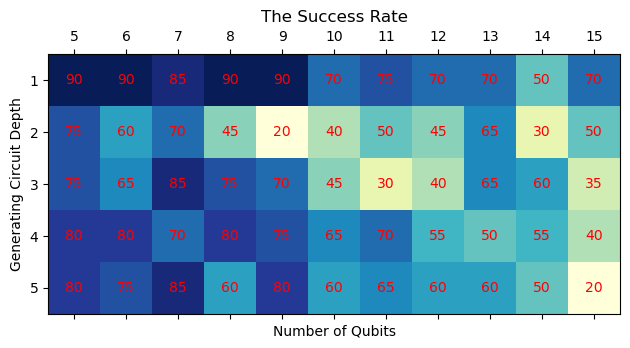

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 示例数据：生成一个二维数组，表示温度分布
# data = np.random.rand(5, 5) * 100  # 生成 10x10 的随机温度数据，范围在 0 到 100 之间

# 创建一个图形和坐标轴
fig, ax = plt.subplots()

# 绘制热力图，使用蓝色系色彩映射
cax = ax.matshow(data_t, cmap='YlGnBu')  # 使用 'Blues' 色彩映射

# 添加颜色条
# fig.colorbar(cax)

# 在每个单元格中显示数值
for (i, j), value in np.ndenumerate(data_t):
    ax.text(j, i, f'{value:.0f}', ha='center', va='center', color='red')

# 设置坐标轴标签

x_ticks = np.arange(data_t.shape[1])
y_ticks = np.arange(data_t.shape[0])
x_labels = list(range(5,16))
y_labels = [1,2,3,4,5]
print(x_ticks,len(x_labels))
ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)
ax.set_xticklabels(x_labels)
ax.set_yticklabels(y_labels)


ax.set_xlabel('Number of Qubits')
ax.set_ylabel('Generating Circuit Depth')
# ax.set_title('The Reducible Rate')
ax.set_title('The Success Rate')
# 显示图形
# plt.show()
plt.tight_layout()
plt.savefig('succ_rate.pdf', format='pdf', bbox_inches='tight')

In [7]:
with open('data_tdd_100.json', 'r') as f:
    data_json = json.load(f)
    
t_tdd = []
g_tdd = []
for k1 in range(5,16):
    for k2 in range(5,6):
        n = k1
        m=k2*n
        # print(n,m)
        # print(data_json[str((n,m))])
        t_tdd.append(data_json[str((n,m))][2])
        g_tdd.append(data_json[str((n,m))][4])

t_tdd2 = []
g_tdd2 = []
for k1 in range(5,16):
    for k2 in range(3,4):
        n = k1
        m=k2*n
        # print(n,m)
        # print(data_json[str((n,m))])
        t_tdd2.append(data_json[str((n,m))][2])
        g_tdd2.append(data_json[str((n,m))][4])

with open('data_qsd_20.json', 'r') as f:
    data_json = json.load(f)
    
t_qsd = []
g_qsd = []
for k1 in range(5,11):
    for k2 in range(5,6):
        n = k1
        m=k2*n
        # print(n,m)
        # print(data_json[str((n,m))])
        t_qsd.append(data_json[str((n,m))][0])
        g_qsd.append(data_json[str((n,m))][1])

t_qsd2 = []
g_qsd2 = []
for k1 in range(5,11):
    for k2 in range(3,4):
        n = k1
        m=k2*n
        # print(n,m)
        # print(data_json[str((n,m))])
        t_qsd2.append(data_json[str((n,m))][0])
        g_qsd2.append(data_json[str((n,m))][1])

print(t_tdd)
print(t_qsd)
print(g_tdd)
print(g_qsd)
t_tdd = [np.log10(k) for k in t_tdd]
t_tdd2 = [np.log10(k) for k in t_tdd2]
t_qsd = [np.log10(k) for k in t_qsd]
t_qsd2 = [np.log10(k) for k in t_qsd2]
g_tdd = [np.log10(k) for k in g_tdd]
g_tdd2 = [np.log10(k) for k in g_tdd2]
g_qsd = [np.log10(k) for k in g_qsd]
g_qsd2 = [np.log10(k) for k in g_qsd2]
print(t_tdd)
print(t_qsd)
print(g_tdd)
print(g_qsd)



[0.11900093756526349, 0.1791156192324055, 0.20795286785472522, 0.34702257882981075, 0.415637837081659, 0.7741275988519192, 0.6841742753982544, 0.7146840453147888, 0.9185511234194733, 2.0155055589146085, 1.1111292498452323]
[0.8047246098518371, 7.3939746737480165, 29.17241277694702, 128.07366210222244, 719.011106300354, 1717.5887318849564]
[26.012048192771083, 34.04477611940298, 39.666666666666664, 49.84126984126984, 58.08196721311475, 72.109375, 93.24, 79.425, 94.5813953488372, 85.72222222222223, 107.78571428571429]
[854.25, 3659.15, 15746.3, 64205.35, 259677.6, 1043970.5]
[-0.924449616945147, -0.7468665411712022, -0.6820350859511572, -0.45964226716249434, -0.3812849238487394, -0.11118744899412335, -0.164833259093687, -0.1458859130283829, -0.03689666733737719, 0.3043840003072841, 0.045764580299729574]
[-0.09435271700357316, 0.8688779586700984, 1.4649723500123808, 2.1074598277952497, 2.856735598821972, 3.2349191822804064]
[1.415174549958157, 1.532050482575822, 1.5984257066728682, 1.6975

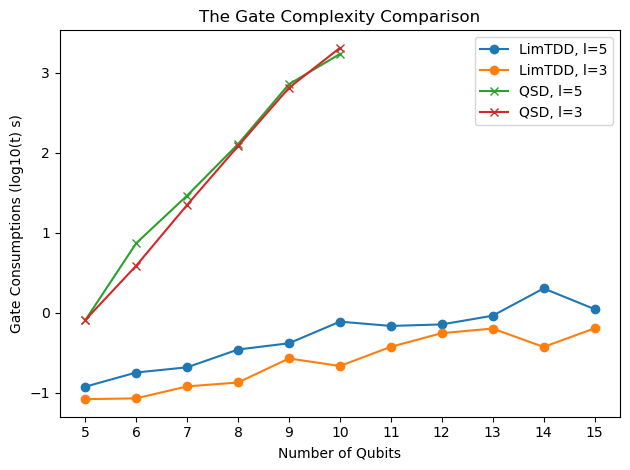

In [9]:
fig, ax = plt.subplots()

# 绘制每个列表的数据
ax.plot(t_tdd, label='LimTDD, l=5',marker='o')
ax.plot(t_tdd2, label='LimTDD, l=3',marker='o')
ax.plot(t_qsd, label='QSD, l=5',marker='x')
ax.plot(t_qsd2, label='QSD, l=3',marker='x')

# 设置图例
ax.legend()

# 设置坐标轴标签和标题

x_ticks = np.arange(11)
x_labels = list(range(5,16))
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels)

ax.set_xlabel('Number of Qubits')
ax.set_ylabel('Gate Consumptions (log10(t) s)')
ax.set_title('The Time Consumption Comparison')

# ax.set_ylabel('Gate Numbers (log10(#gates))')
ax.set_title('The Gate Complexity Comparison')
# 显示图形
# plt.show()
plt.tight_layout()
plt.savefig('time_comp_100.pdf', format='pdf', bbox_inches='tight')

[[ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.5       +0.j -0.5       +0.j -0.5       +0.j -0.5       +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]
 [ 0.5       +0.j -0.5       +0.j  0.5       +0.j  0.5       +0.j]]


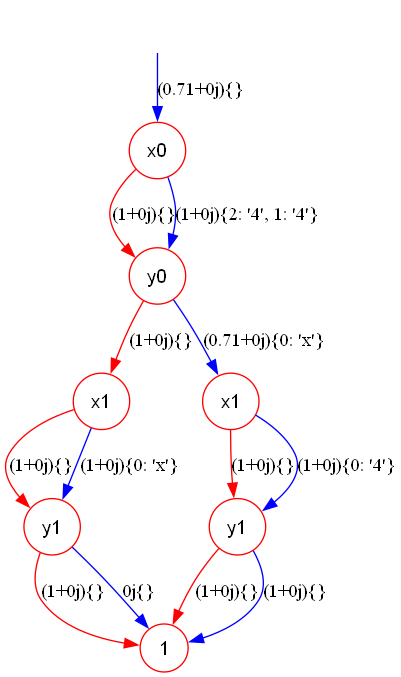

In [15]:
n=2
m=5*n
# cir=gen_cir('Random_Clifford_T',n,m)
cir=QuantumCircuit(2)
# cir.t(0)
cir.cz(0,1)
cir.h(0)
# cir.h(1)
# cir.x(0)
cir.ch(0,1)
cir.cx(0,1)
# cir.h(0)
# cir.h(1)
# cir.x(0)
U = Operator(cir).data
print(U)
tdd=simulate(cir,True)
# id_tdd,cir_head,cir_end=merge_split(tdd)
tdd.show(True)

[[3, 1], [2, 0]]
[[2, 0]]


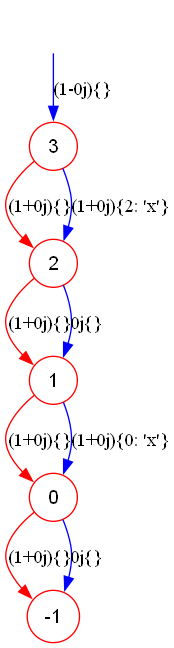

In [16]:
# tdd=simulate(cir,True)
id_tdd,cir_head,cir_end=merge_split(tdd)
# print(cir_head,cir_end)
id_tdd.show(False)

In [17]:
print(cir_head.data)
cir_head.draw()

[CircuitInstruction(operation=Instruction(name='unitary', num_qubits=1, num_clbits=0, params=[array([[ 0.70710678-0.00000000e+00j,  0.70710678-0.00000000e+00j],
       [ 0.70710678-0.00000000e+00j, -0.70710678-8.65956056e-17j]])]), qubits=(Qubit(QuantumRegister(2, 'q'), 0),), clbits=()), CircuitInstruction(operation=Instruction(name='cp', num_qubits=2, num_clbits=0, params=[3.141592653589793]), qubits=(Qubit(QuantumRegister(2, 'q'), 0), Qubit(QuantumRegister(2, 'q'), 1)), clbits=())]


┌─────────┐       
q_0: ┤ Unitary ├─■─────
     └─────────┘ │P(π) 
q_1: ────────────■─────

In [18]:
print(cir_end.data)
cir_end.draw()

[CircuitInstruction(operation=Instruction(name='cx', num_qubits=2, num_clbits=0, params=[]), qubits=(Qubit(QuantumRegister(2, 'q'), 0), Qubit(QuantumRegister(2, 'q'), 1)), clbits=()), CircuitInstruction(operation=Instruction(name='c-unitary', num_qubits=2, num_clbits=0, params=[array([[ 0.70710678+0.j,  0.70710678+0.j],
       [-0.70710678+0.j,  0.70710678+0.j]])]), qubits=(Qubit(QuantumRegister(2, 'q'), 0), Qubit(QuantumRegister(2, 'q'), 1)), clbits=()), CircuitInstruction(operation=Instruction(name='cp', num_qubits=2, num_clbits=0, params=[3.141592653589793]), qubits=(Qubit(QuantumRegister(2, 'q'), 0), Qubit(QuantumRegister(2, 'q'), 1)), clbits=())]


q_0: ──■───────■──────■─────
     ┌─┴─┐┌────┴────┐ │P(π) 
q_1: ┤ X ├┤ Unitary ├─■─────
     └───┘└─────────┘

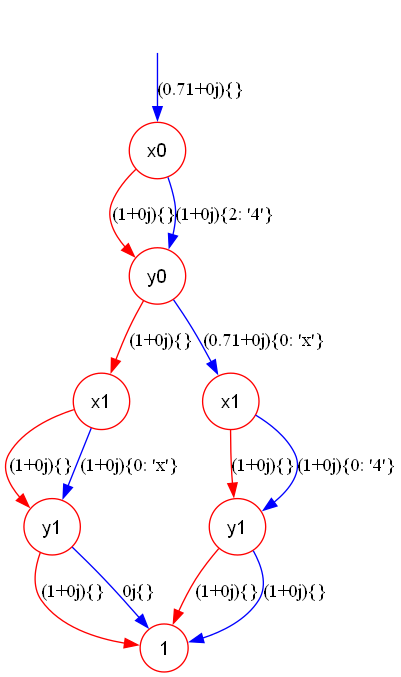

In [134]:
# # np.sin(np.pi/8)
# w = -0.35355339-0.35355339j
# # np.angle(w)/np.pi
# abs(w)*np.exp(-np.pi*3/4*1j)
cir_head2 = QuantumCircuit(2)
cir_end2 = QuantumCircuit(2)
cir_head2.data = [cir_head.data[-1]]
tdd_new = update_tdd(tdd,cir_head2,cir_end2)
tdd_new.show()